Import Required Libraries

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [19]:

train = pd.read_csv("fashion-mnist_train.csv")
test = pd.read_csv("fashion-mnist_test.csv")

print("Training data:", train.shape)
print("Testing data:", test.shape)


Training data: (60000, 785)
Testing data: (10000, 785)


In [10]:
X_train = train.drop("label", axis=1)
y_train = train["label"]

X_test = test.drop("label", axis=1)
y_test = test["label"]

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 784)
(60000,)
(10000, 784)
(10000,)


Noramlize and get a smaller dataset to make the processing faster

In [11]:
X_train = X_train / 255.0
X_test = X_test / 255.0

X_train = X_train[:5000]
y_train = y_train[:5000]

X_test = X_test[:1000]
y_test = y_test[:1000]


In [16]:

k_values = [1, 3, 5, 7, 9]
accuracies=[]

for k in k_values:

    start = time.time()

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

    end = time.time()

    print(
        "k =", k,
        "| Accuracy =", round(accuracy, 4),
        "| Time =", round(end - start, 2), "seconds"
    )


k = 1 | Accuracy = 0.802 | Time = 0.08 seconds
k = 3 | Accuracy = 0.815 | Time = 0.08 seconds
k = 5 | Accuracy = 0.811 | Time = 0.1 seconds
k = 7 | Accuracy = 0.817 | Time = 0.09 seconds
k = 9 | Accuracy = 0.813 | Time = 0.08 seconds


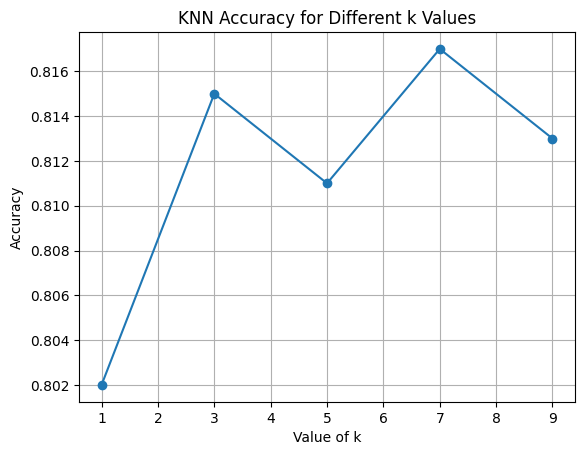

In [17]:

plt.plot(k_values, accuracies, marker="o")

plt.xlabel("Value of k")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different k Values")

plt.grid()
plt.show()


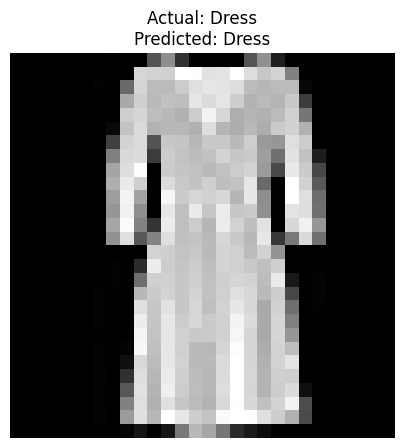

In [21]:
# Sample image classification
best_k = k_values[np.argmax(accuracies)]
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
sample_index = 10

sample_image = X_test.iloc[sample_index].values.reshape(28, 28)

prediction = knn.predict(X_test.iloc[[sample_index]])[0]
actual = y_test.iloc[sample_index]

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(5, 5))
plt.imshow(sample_image, cmap="gray")

plt.title(
    "Actual: " + class_names[actual] +
    "\nPredicted: " + class_names[prediction]
)

plt.axis("off")
plt.show()